# STRIDE explanation API: a minimal tour

One short example per explanation method in `stride.xai`, all on the same SEA stream:
a reference block of 1000 samples (SEA variant 0) and a detection block of 1000
samples (SEA variant 3). Recurring-concept analysis needs many windows, so it uses
a multi-window SEA stream with the same 1000-sample block size.

| Section | Layer | API |
|---|---|---|
| 1 | Data | `DescriptiveStatisticsDriftDetector` |
| 2 | Data | `StatisticalTestsDriftDetector` |
| 3 | Data | `ClusterBasedDriftDetector` |
| 4 | Explanation | `DecisionBoundaryDriftAnalyzer` (SSNP + disagreement tree) |
| 5 | Explanation | `FeatureImportanceDriftAnalyzer` (PFI, SHAP, LIME, abstention) |
| 6 | Explanation | `FullWindowStorage` + `cluster_windows` (recurring concepts) |

Requires the full install: `pip install -e ".[all]"` (SHAP/LIME, HDBSCAN/X-Means, TensorFlow for SSNP).

## 0. Data: SEA, two blocks of 1000

In [1]:
import io
import os
import warnings
from contextlib import redirect_stderr, redirect_stdout

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # quiet TensorFlow C++ logs

import pandas as pd

from stride.datasets import SeaDriftDataset

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*(midrank|p-value capped).*")  # SciPy anderson_ksamp notices
%matplotlib inline

BLOCK = 1000
SEED = 42

X, y = SeaDriftDataset().generate(n_samples_before=BLOCK, n_samples_after=BLOCK, random_seed=SEED)

# Reference (pre-drift) and detection (post-drift) blocks.
# reset_index: some detectors align X and y by index (see section 1).
X_ref, y_ref = X.iloc[:BLOCK].reset_index(drop=True), y.iloc[:BLOCK].reset_index(drop=True)
X_det, y_det = X.iloc[BLOCK:].reset_index(drop=True), y.iloc[BLOCK:].reset_index(drop=True)

print(X.shape, list(X.columns), "classes:", sorted(y.unique()))
X_ref.head()

I0000 00:00:1792322744.759145   64460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322744.759972   64460 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322746.803956   64460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322746.804505   64460 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


(2000, 3) ['X1', 'X2', 'X3'] classes: [False, True]


,X1,X2,X3
0,6.394268,0.250108,2.750293
1,2.232107,7.364712,6.766995
2,8.921796,0.869388,4.219218
3,0.297972,2.186380,5.053553
4,0.265360,1.988377,6.498844


## 1. Descriptive statistics

Per-class relative shifts of mean, std, min, max, median and the class imbalance ratio.

In [2]:
from stride.xai.stats import DescriptiveStatisticsDriftDetector, StatisticsType

desc = DescriptiveStatisticsDriftDetector(X_ref, y_ref, X_det, y_det, decision_thr=0.4)
drift, details = desc.detect(StatisticsType.All, thr=0.2)
print("Drift:", drift)
desc.calculate_stats_before_after()

Drift: True


new                                                    \
                   X1                            X2                       
                 mean    median       std      mean    median       std   
(label, id)                                                               
False        3.376809  2.992343  2.261157  3.048751  2.665270  2.194786   
True         6.557510  7.028549  2.491358  6.456122  6.884984  2.423172   

                                                old                      \
                   X3                            X1                       
                 mean    median       std      mean    median       std   
(label, id)                                                               
False        5.063686  5.128165  2.841479  2.810211  2.482188  1.858859   
True         4.872776  4.906035  2.944287  6.209949  6.722816  2.604993   

                                                                         
                   X2                            X3                      
                 mean    median       std      mean    median       std  
(label, id)                                                              
False        2.568577  2.284936  1.837715  4.955604  5.073277  2.834728  
True         6.029189  6.366179  2.600671  4.954822  5.025731  2.930413

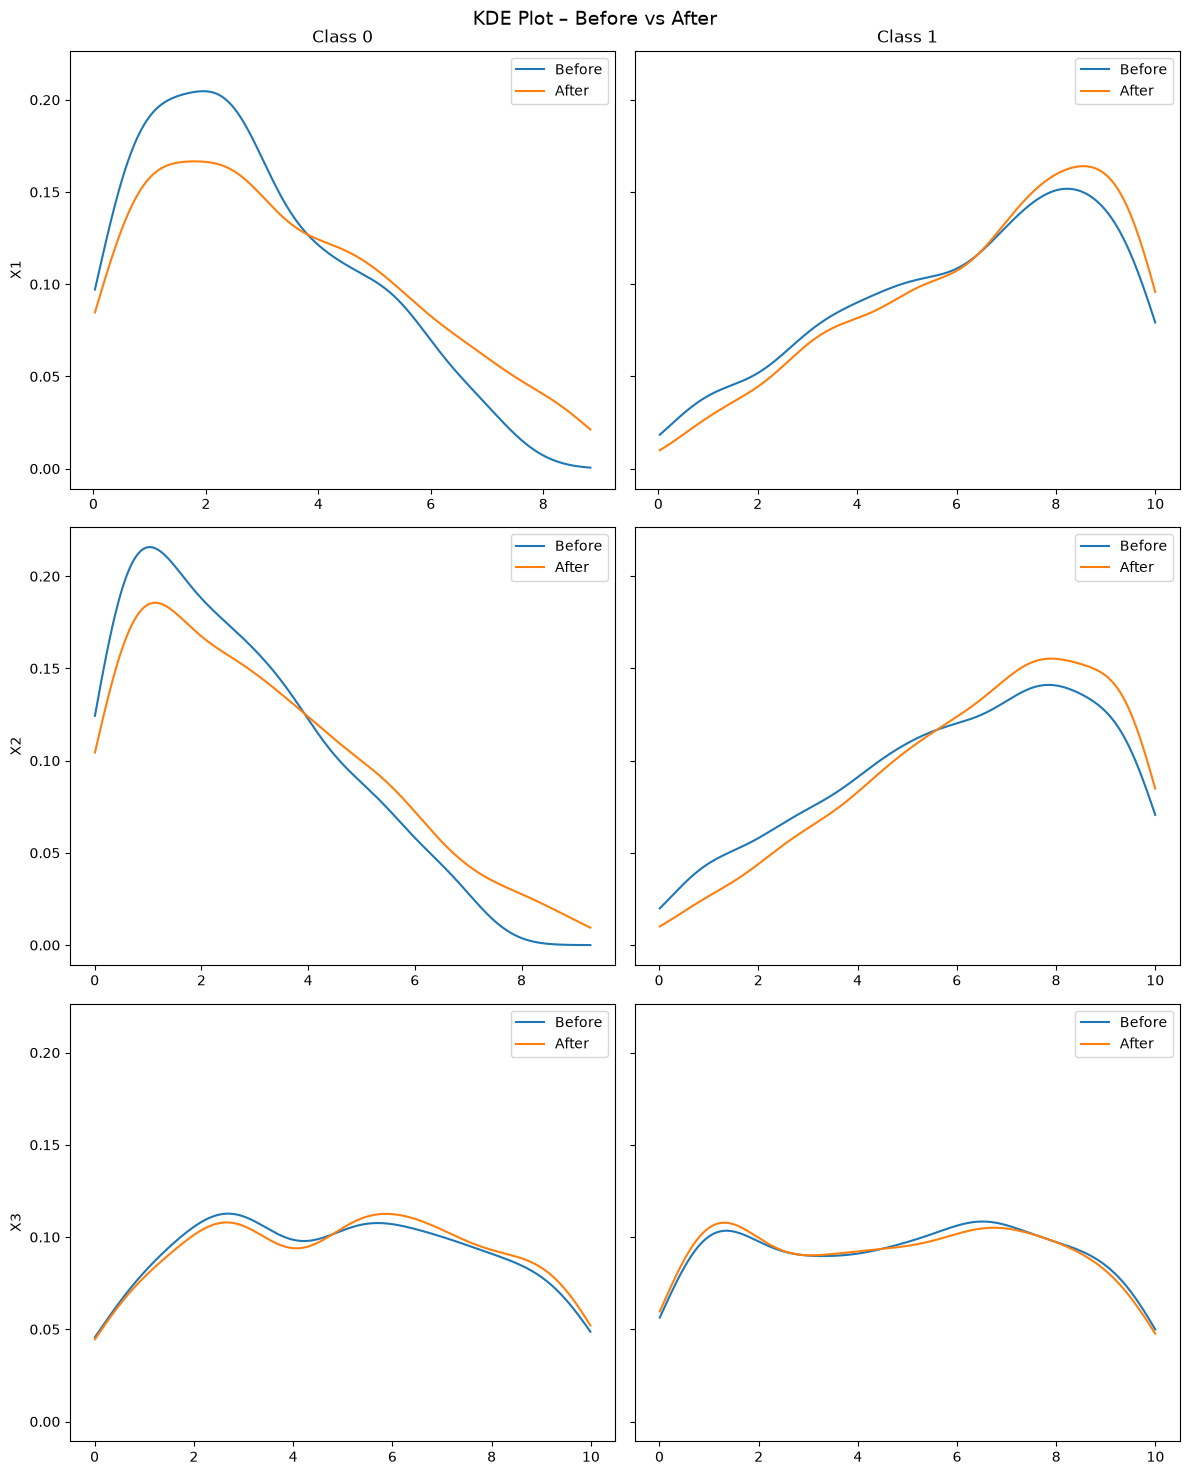

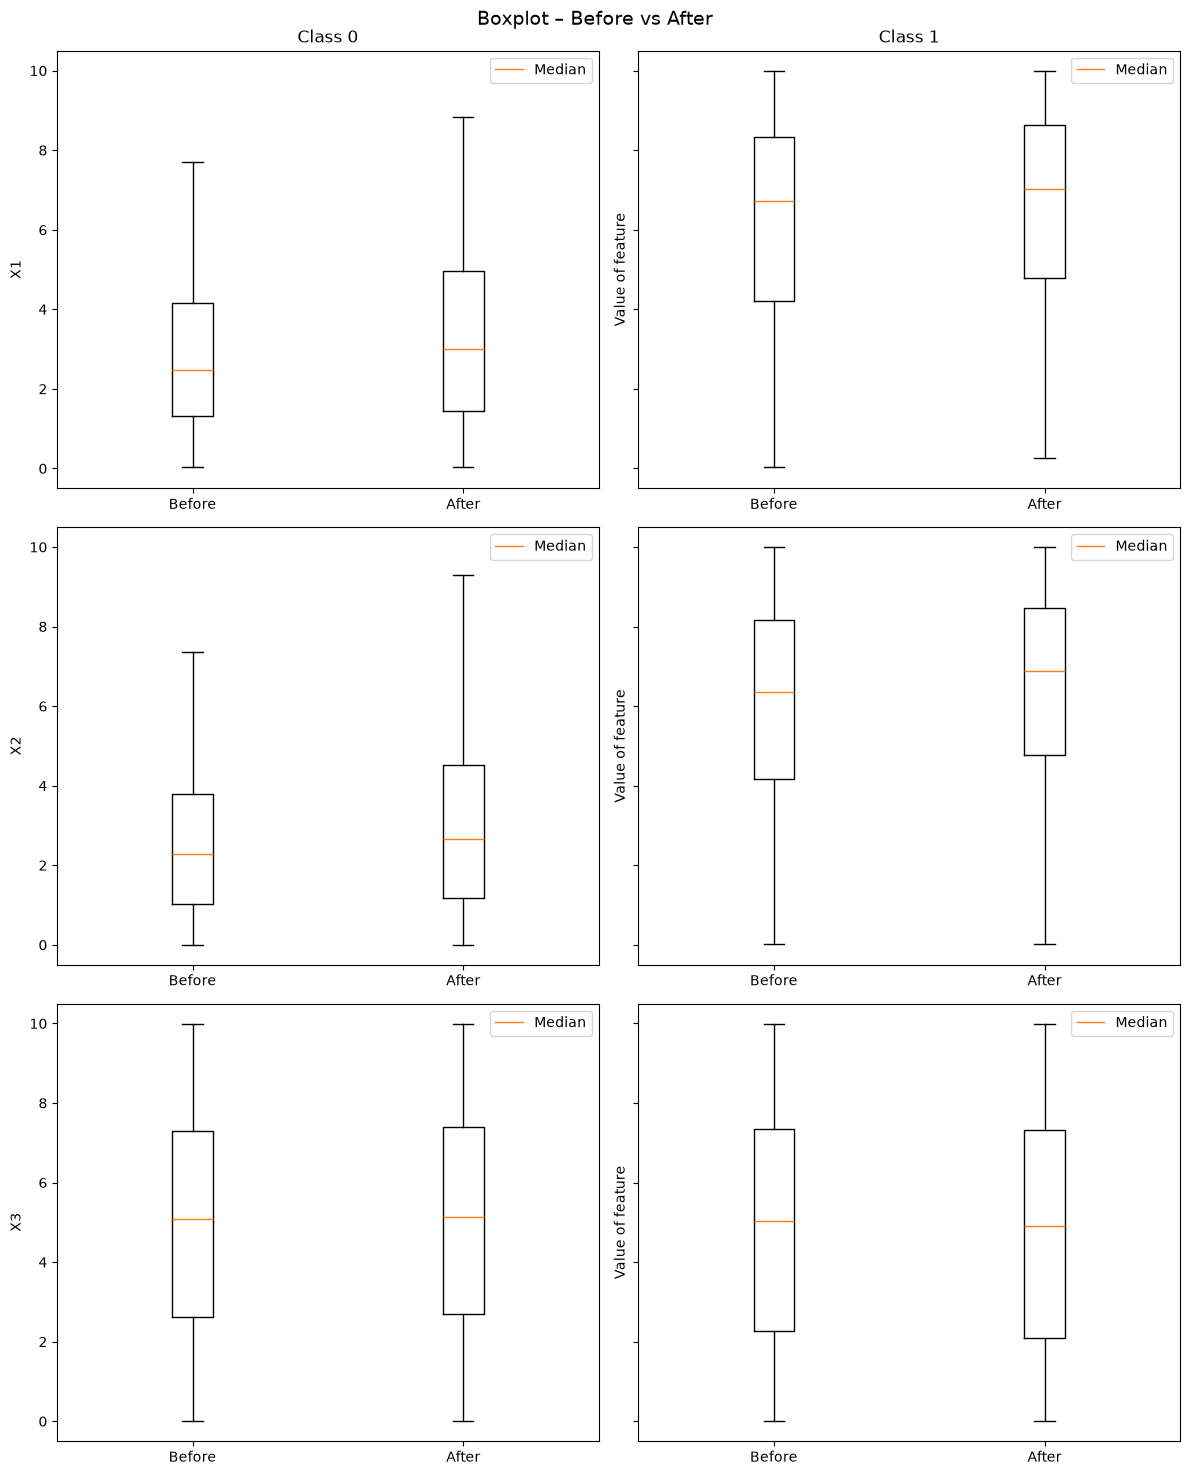

In [3]:
from stride.xai.stats import PlotOptions, plot_boxplot, plot_kde

fig_kde = plot_kde(X_ref, y_ref, X_det, y_det)
fig_box = plot_boxplot(X_ref, y_ref, X_det, y_det, show_=PlotOptions.Median)

## 2. Statistical tests

Two-sample tests and divergences on class-conditional marginals P(X | Y=y).

In [4]:
from stride.xai.stats import StatisticalTestsDriftDetector, StatisticalTestType

tests = StatisticalTestsDriftDetector(X_ref, y_ref, X_det, y_det)
print("Drift:", tests.detect(StatisticalTestType.All))
pd.Series(tests.drift_flags, name="drift")

Drift: False


kolmogorov_smirnov    False
kullback_leibler      False
wasserstein           False
jensen_shannon        False
spearman               True
anderson_darling       True
Name: drift, dtype: bool

In [5]:
# Per-test, per-class, per-feature diagnostics, e.g. Kolmogorov-Smirnov:
tests.drift_details[StatisticalTestType.KolmogorovSmirnov.value]

{False: {'X1': {'drift': True,
   'p_value': 0.02865719141827943,
   'stat': 0.1081931072758246},
  'X2': {'drift': False,
   'p_value': 0.10018469920391652,
   'stat': 0.09068765368339102},
  'X3': {'drift': False,
   'p_value': 0.9961786967601469,
   'stat': 0.02956116888022138}},
 True: {'X1': {'drift': False,
   'p_value': 0.2620734435546556,
   'stat': 0.05619878762279028},
  'X2': {'drift': False,
   'p_value': 0.08078181467418885,
   'stat': 0.07082676482346108},
  'X3': {'drift': False,
   'p_value': 0.999873827416831,
   'stat': 0.01825102896178573}}}

## 3. Clustering dynamics

X-Means inside each class, Hungarian matching of clusters across blocks, then four
criteria: cluster count, descriptive stats, centroid shift, dispersion.

In [6]:
from stride.xai.clustering import ClusterBasedDriftDetector

clus = ClusterBasedDriftDetector(X_ref, y_ref, X_det, y_det, random_state=SEED)
drift, details = clus.detect()
print("Drift:", drift, "| strength:", round(clus.strength_of_drift, 3))
print("Clusters before/after:", clus.number_of_clusters_old, "/", clus.number_of_clusters_new)
details

Drift: True | strength: 0.864
Clusters before/after: 5 / 7


{False: {'nr_of_clusters': True,
  'centroid_shift': {0: True, 1: True, 5: True},
  'desc_stats_changes': {0: {'X1': {'mean': True, 'median': True, 'std': True},
    'X2': {'mean': True, 'median': True, 'std': False},
    'X3': {'mean': False, 'median': False, 'std': False}},
   1: {'X1': {'mean': False, 'median': False, 'std': False},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': False, 'median': False, 'std': False}},
   5: {'X1': {'mean': True, 'median': True, 'std': True},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': True, 'median': True, 'std': True}}},
  'avg_distance_to_center': {0: False, 1: False, 5: True}},
 True: {'nr_of_clusters': True,
  'centroid_shift': {2: True, 3: True, 4: True, 6: True},
  'desc_stats_changes': {2: {'X1': {'mean': True,
     'median': True,
     'std': False},
    'X2': {'mean': True, 'median': True, 'std': True},
    'X3': {'mean': False, 'median': False, 'std': False}},
   3: {'X1': {'mean': F

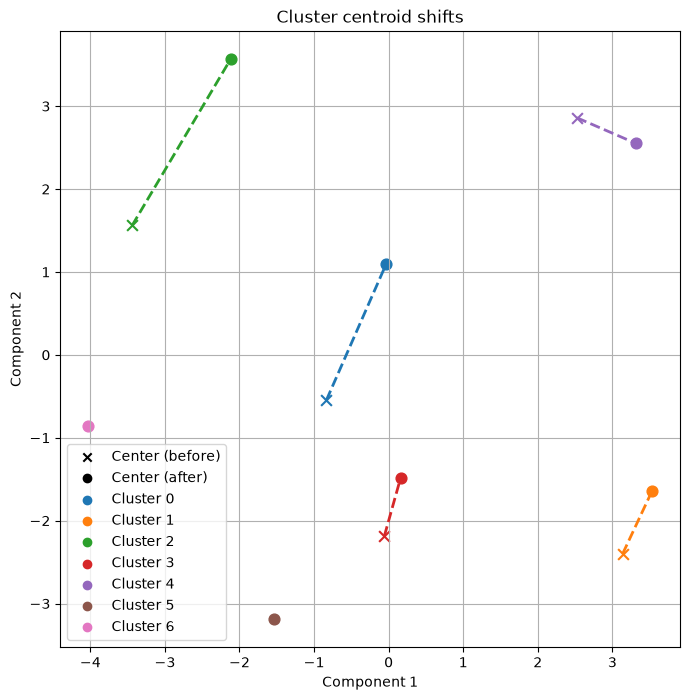

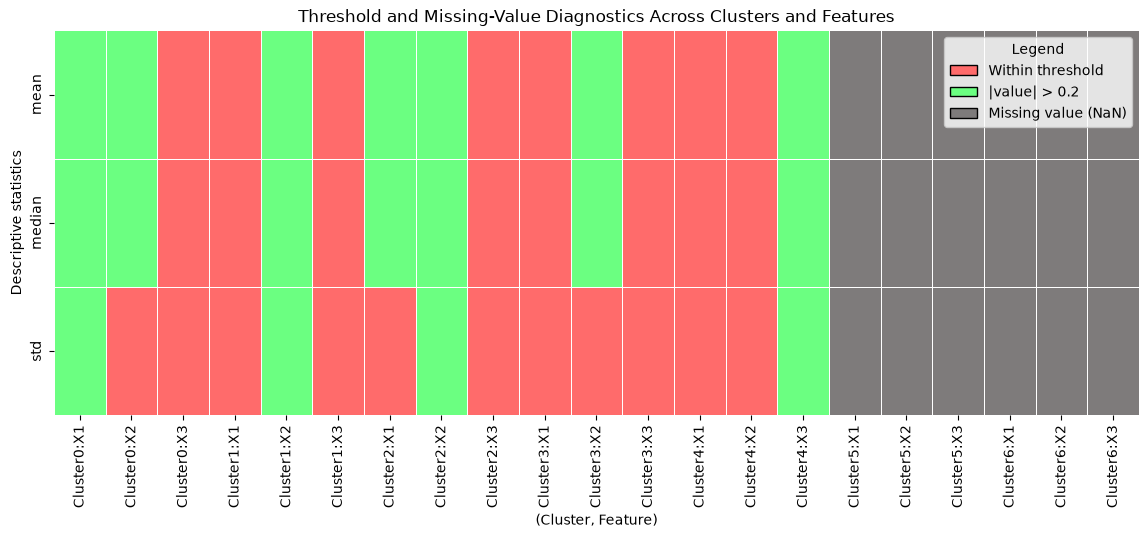

In [7]:
from stride.xai.clustering import plot_centers_shift, plot_clustering_heatmap

# Plots work in 2D; DataFrames with more columns are reduced with PCA automatically.
fig_centers = plot_centers_shift(X_ref, X_det, y_ref, y_det, clus.cluster_labels_old, clus.cluster_labels_new)
fig_heat = plot_clustering_heatmap(clus.stats_shifts, threshold=clus.thr_desc_stats)

## 4. Decision boundary shift (SDBM)

SEA has 3 features, so the analyzer fits an SSNP projection to 2D (TensorFlow),
trains one classifier per block, renders both decision maps, and fits a disagreement
tree that describes where the two classifiers disagree.

In [8]:
from stride.models import RandomForestModel
from stride.xai.boundary import DecisionBoundaryDriftAnalyzer

db = DecisionBoundaryDriftAnalyzer(X_ref, y_ref, X_det, y_det, random_state=SEED)
with redirect_stdout(io.StringIO()):  # hide Keras progress bars printed by SSNP
    db_res = db.analyze(model_class=RandomForestModel, grid_size=150, feature_names=list(X.columns))
print("Disagreement rate on detection block:", round(db_res["disagreement"]["drift_rate"], 3))
db_res["disagreement"]["disagreement_table"]

Disagreement rate on detection block: 0.13


,Rule Label,Rule,Drift Conf.,Samples,Coverage,Visual Area,Leaf_ID
0,Rule 1,"X2 ∈ [4.01, 4.88], X1 ∈ [0.03, 3.95]",62.9%,26,2.6%,1.0%,5
1,Rule 2,"X2 ∈ [4.01, 4.88], X1 ∈ [3.95, 4.88]",98.5%,17,1.7%,11.3%,6


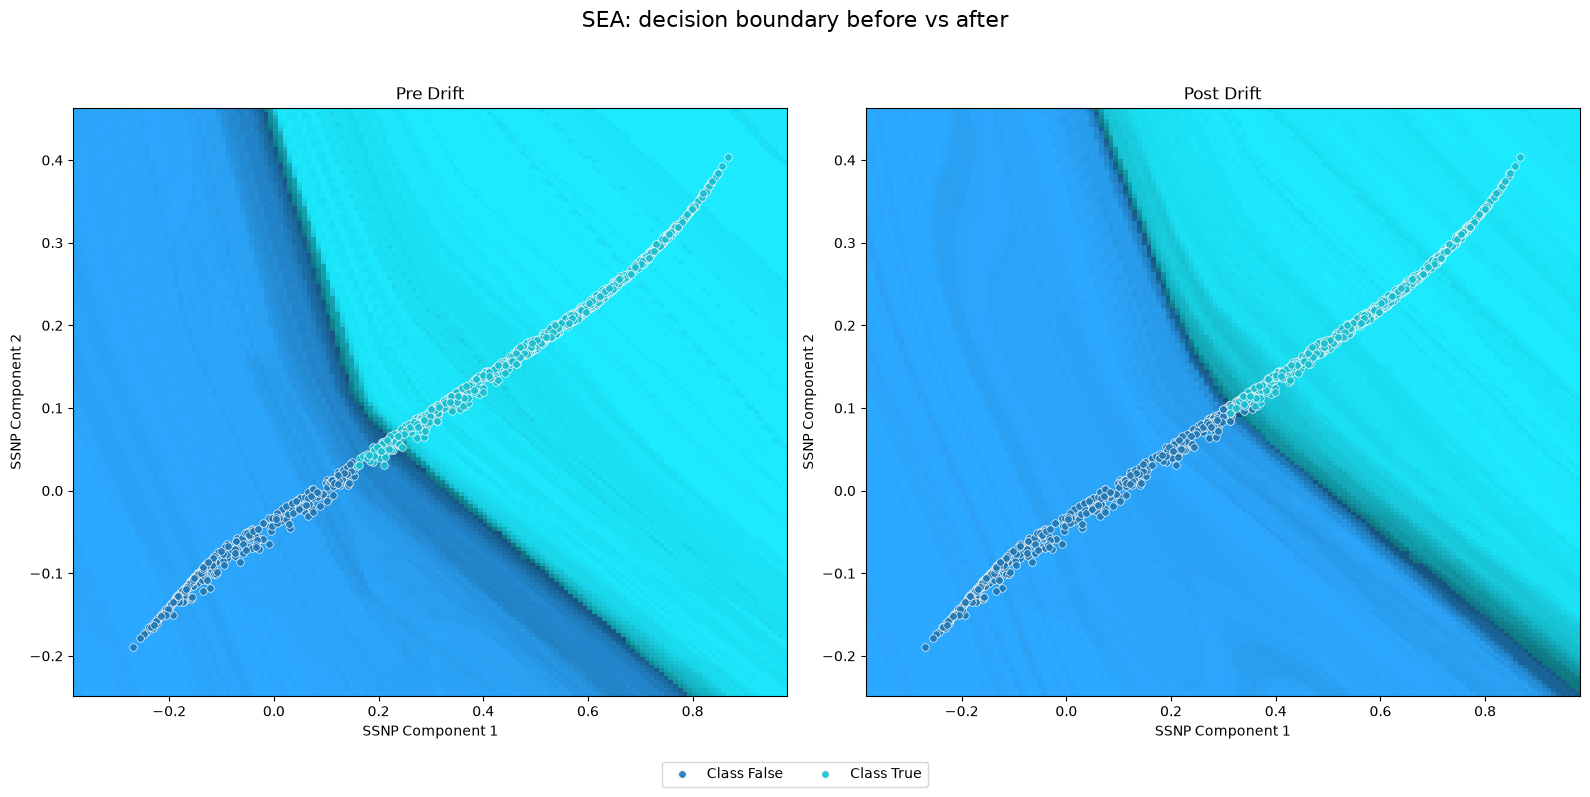

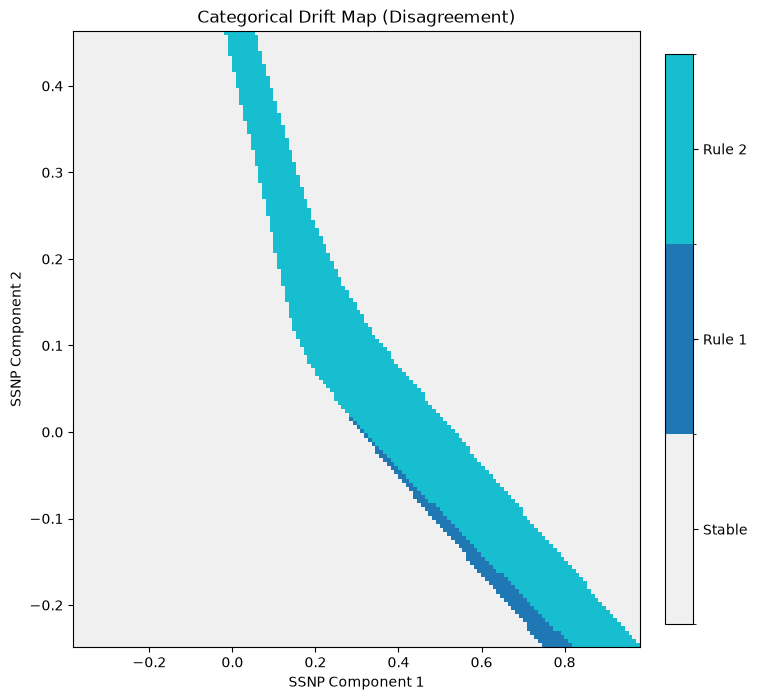

In [9]:
from stride.xai.boundary.visualization import plot_categorical_drift_map, visualize_decision_boundary

fig_db = visualize_decision_boundary(db_res, title="SEA: decision boundary before vs after")
with redirect_stdout(io.StringIO()):  # the drift map also calls SSNP.inverse_transform
    fig_map = plot_categorical_drift_map(
        db_res["ssnp_model"],
        db_res["disagreement"]["viz_tree"],
        db_res["disagreement"]["drift_leaf_ids"],
        db_res["post"]["grid_bounds"],
        grid_size=db_res["grid_size"],
        is_2d=db_res["is_2d"],
    )

## 5. Feature importance

Two questions, one analyzer:

* **Data-centric** (`compute_drift_importance`): train a discriminator to tell the
  reference block (t=0) from the detection block (t=1) and explain it. With
  `include_target=False` it explains covariate shift P(X); with `include_target=True`
  the label is an input too, so it captures concept drift P(Y | X).
* **Model-centric** (`compute_predictive_importance_shift`): train one classifier
  per block and compare which features each relies on to predict Y.

Methods: `"permutation"` (PFI), `"shap"`, `"lime"`.

In [10]:
from stride.xai.importance import (
    FeatureImportanceDriftAnalyzer,
    FeatureImportanceMethod,
    visualize_drift_importance,
    visualize_predictive_importance_shift,
)

fi = FeatureImportanceDriftAnalyzer(X_ref, y_ref, X_det, y_det)
rf = dict(model_class=RandomForestModel, model_params={"random_state": SEED})

rows = {}
with redirect_stderr(io.StringIO()):  # hide SHAP's tqdm progress bar
    for include_target in (False, True):
        for method in FeatureImportanceMethod.all_available():
            res = fi.compute_drift_importance(importance_method=method, include_target=include_target, **rf)
            rows[("P(Y|X)" if include_target else "P(X)", method)] = dict(
                zip(res["feature_names"], res["importance_mean"]), discriminator_acc=res["accuracy"]
            )
pd.DataFrame(rows).T.round(3)

I0000 00:00:1792322769.252401   65290 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322769.253181   65290 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322769.419420   65288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322769.420485   65288 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322769.668707   65289 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322769.670145   65289 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322772.023960   65290 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322772.025108   65290 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322772.128112   65288 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322772.128524   65288 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322772.345033   65289 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322772.345548   65289 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322808.864784   65298 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322808.865714   65298 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322808.926980   65293 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322808.927657   65293 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322808.983029   65292 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different com

I0000 00:00:1792322809.119666   65295 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322809.120551   65295 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322811.392693   65298 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322811.393394   65298 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322811.497944   65293 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322811.498724   65293 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322811.526280   65292 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different com

I0000 00:00:1792322811.660986   65295 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322811.661852   65295 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


X1     X2     X3  discriminator_acc
P(X)   permutation -0.001  0.003 -0.001              0.500
       shap         0.013  0.012  0.013              0.500
       lime         0.003  0.002  0.006              0.500
P(Y|X) permutation  0.016  0.016 -0.000              0.565
       shap         0.125  0.127  0.015              0.565
       lime         0.147  0.150  0.005              0.565

I0000 00:00:1792322847.581888   65291 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322847.582467   65291 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322847.585180   65296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322847.586180   65296 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322847.696576   65297 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different com

I0000 00:00:1792322849.866305   65291 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322849.867039   65291 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322849.875934   65296 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322849.876495   65296 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322850.059498   65297 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different com

I0000 00:00:1792322850.083896   65294 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322850.084620   65294 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


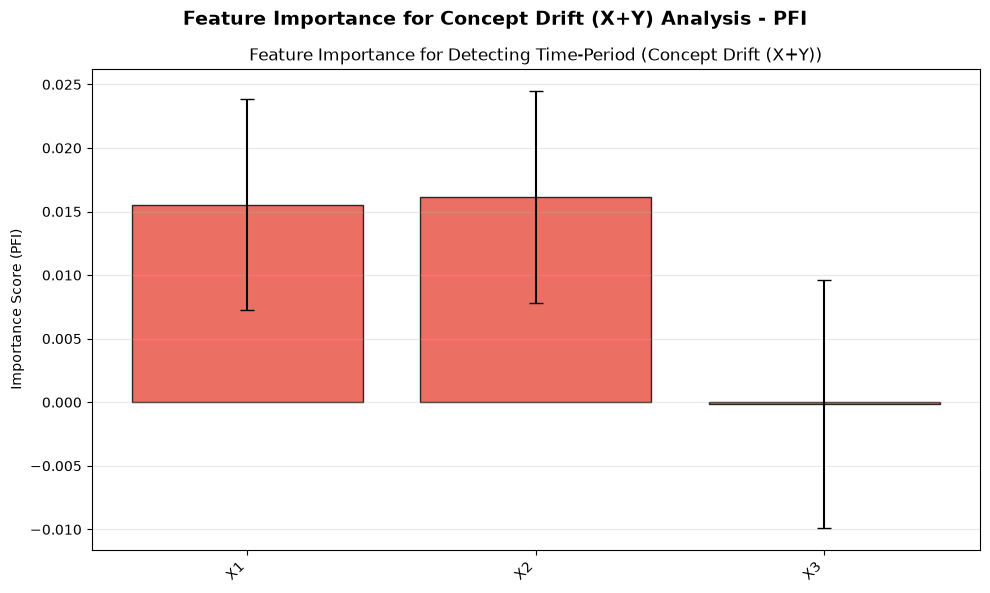

In [11]:
# Concept-drift attribution with PFI, plotted
res = fi.compute_drift_importance(importance_method="permutation", include_target=True, **rf)
fig_fi = visualize_drift_importance(res, res["feature_names"], plot_type="bar", include_target=True)

**Selective localization.** With an abstention strategy, the analyzer keeps only the
samples the discriminator is confident about (the drift locus) and explains those.

In [12]:
from stride.xai.importance import AbstainStrategy

for strategy in AbstainStrategy.all_available():
    res = fi.compute_drift_importance(importance_method="permutation", include_target=True, abstain_strategy=strategy, **rf)
    print(
        f"{strategy:22s} coverage={res['drift_coverage']:.2f} "
        f"selective_acc={res['selective_accuracy']:.2f} fallback={res['drift_locus_fallback']} "
        f"importance={dict(zip(res['feature_names'], res['importance_mean'].round(3)))}"
    )

I0000 00:00:1792322855.545826   65299 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322855.546685   65299 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792322857.471261   65299 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322857.471813   65299 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


confidence_threshold   coverage=0.13 selective_acc=1.00 fallback=False importance={'X1': 0.12, 'X2': 0.114, 'X3': 0.0}


/tmp/ipykernel_64460/3729449612.py:4: UserWarning: Identified drift locus contains only 17 samples (< min_samples=20). Falling back to full-dataset evaluation for feature importance.
  res = fi.compute_drift_importance(importance_method="permutation", include_target=True, abstain_strategy=strategy, **rf)


conformal              coverage=0.01 selective_acc=1.00 fallback=True importance={'X1': 0.016, 'X2': 0.016, 'X3': -0.0}


Accuracy before/after: 1.0 / 1.0


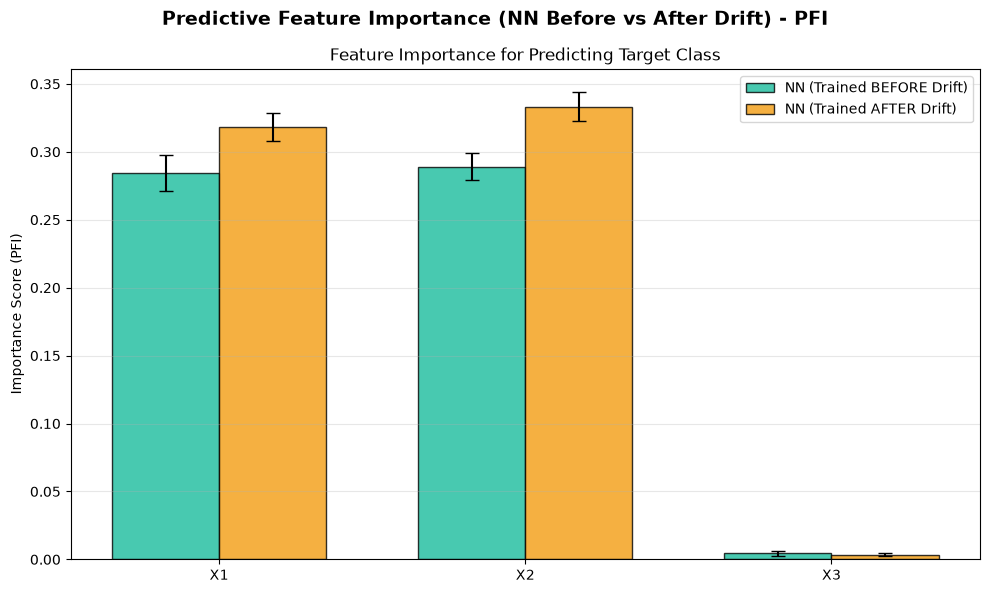

In [13]:
shift = fi.compute_predictive_importance_shift(importance_method="permutation", **rf)
print("Accuracy before/after:", round(shift["accuracy_before"], 3), "/", round(shift["accuracy_after"], 3))
fig_shift = visualize_predictive_importance_shift(shift, list(X.columns), plot_type="bar")

## 6. Recurring concepts (prototypes + HDBSCAN)

Split a long stream into 1000-sample windows, select class prototypes per window
with an online model, compute a window-to-window distance matrix and cluster it.
Windows in the same cluster share a concept, so a cluster that comes back is a
recurring concept.

This section uses `RandomTreeMultiWindowDataset` instead of SEA: its concept flips at
each drift position, so drifts at windows 10 and 20 give the pattern A, B, A. With
`SeaMultiWindowDataset` (seed 42, variants 3, 2, 3) the concepts are too similar for the
prototype distances to separate, and HDBSCAN marks every window as an outlier (-1).

In [14]:
from river import forest

from stride.datasets import RandomTreeMultiWindowDataset
from stride.xai.recurrence import FullWindowStorage, cluster_windows, get_drift_from_clusters
from stride.xai.recurrence.methods import create_prototypes_for_stream, prepare_dataset_from_generator

DRIFTS = [10 * BLOCK, 20 * BLOCK]
X_s, y_s = RandomTreeMultiWindowDataset().generate(
    num_windows=30, window_length=BLOCK, drift_positions=DRIFTS, random_seed=SEED
)
windows = prepare_dataset_from_generator(X_s, y_s, window_size=BLOCK)

storage = FullWindowStorage()
create_prototypes_for_stream(forest.ARFClassifier(seed=SEED), storage, windows, verbose=False)
print(len(storage.get_all_iterations()), "windows stored")

30 windows stored


In [15]:
dist = storage.compute_distance_matrix(measure="centroid_displacement")
labels = cluster_windows(dist)
print("Cluster per window:", labels.tolist())
print("Detected drift windows:", get_drift_from_clusters(labels), "| true:", [d // BLOCK for d in DRIFTS])

Cluster per window: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Detected drift windows: [10, 20] | true: [10, 20]


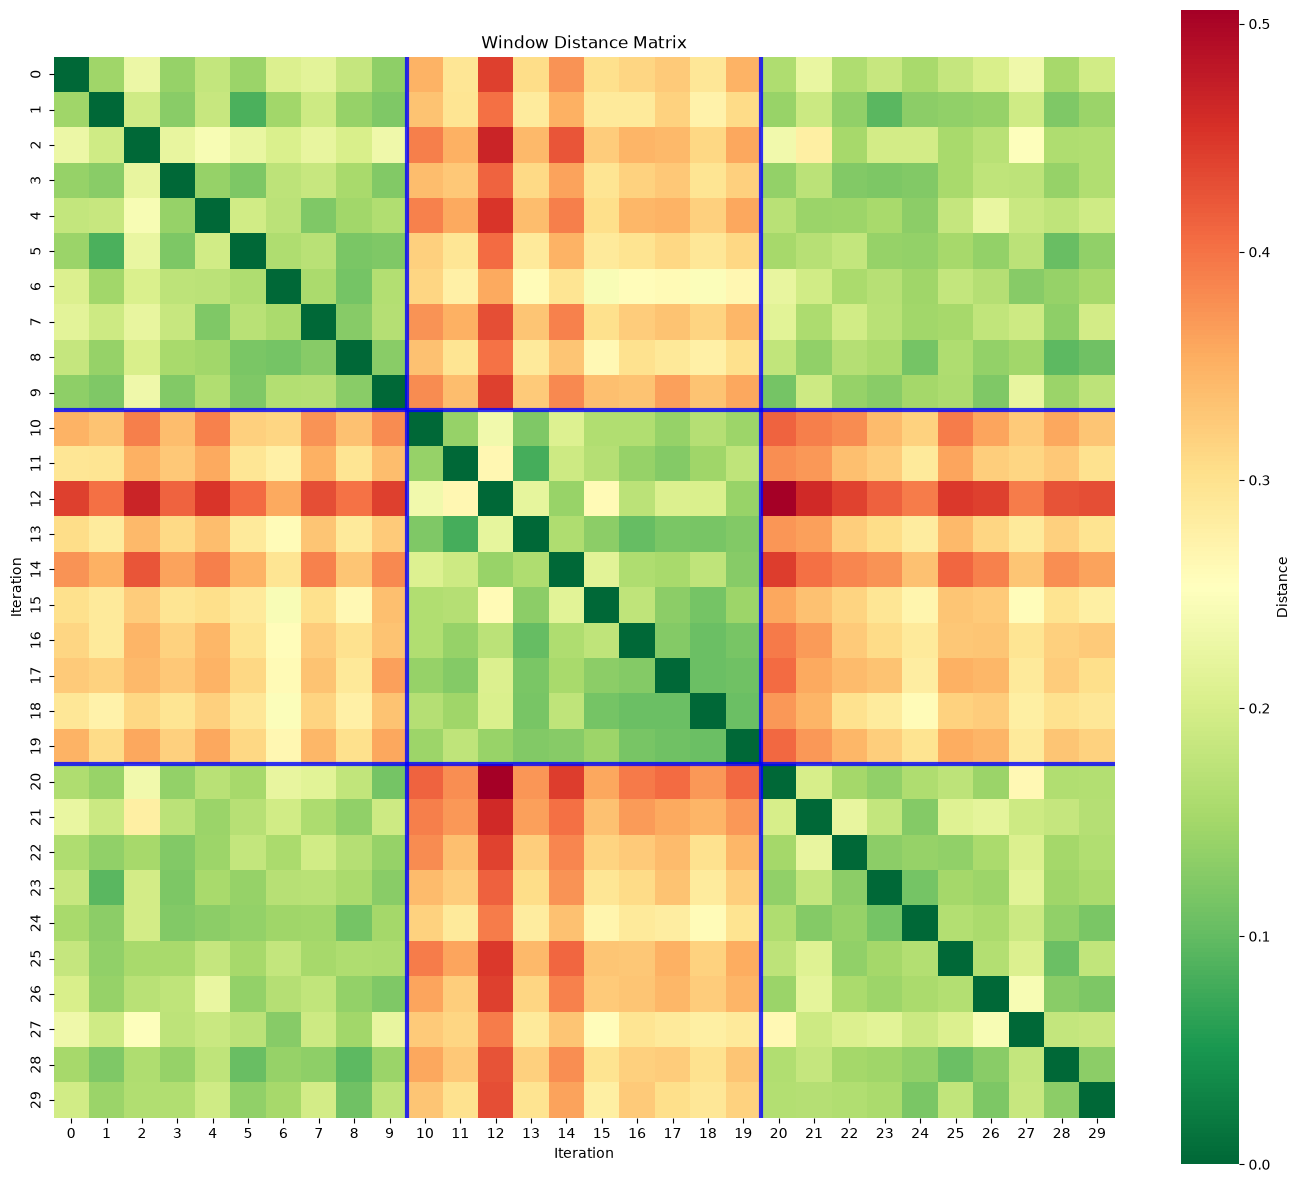

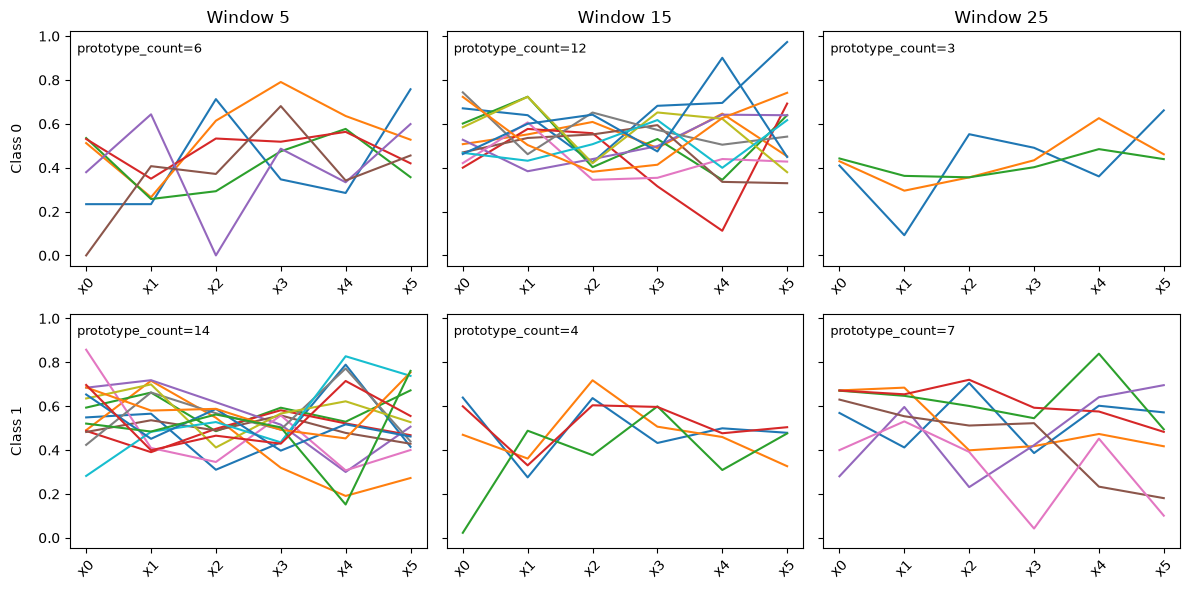

In [16]:
from stride.xai.recurrence.visualization import plot_prototype_comparison, visualize_distance_matrix

fig_dist = visualize_distance_matrix(dist, drift_positions=[d // BLOCK for d in DRIFTS])
fig_protos = plot_prototype_comparison(storage, windows_to_compare=[5, 15, 25])